# Health Data Analysis

## 1. Data import
Här förbereds projektet genom att nödvändiga bibliotek importeras
och hälsodatan läses in för vidare analys

In [15]:
import pandas as pd
from src.data_loader import load_data

df = load_data()

## 2. Data Overview
I det här avsnittet undersöks datasetets struktur och innehåll.
Vi tittar bland annat på antalet observationer, tillgängliga variabler och hur datan är uppbyggd

In [22]:
df.head()


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [23]:
df.shape

(800, 9)

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [25]:
df.describe()


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


In [20]:
df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(0)

## Data Overview Summary

Datasetet innehåller 800 observationer och 9 variabler

Det finns inga saknade värden i datasetet

Inga duplicerade rader har upptäckts

Samtilga kolumner innehåller 800 giltliga värden

## 3. exploratory Data Analysis
I det här avsnittet undersöks datasetets innehåll mer ingående.
Genom diagram och statistiska sammanställningar letar vi efter
mönster och fördelningar i de olika hälsovariablerna

3.1, Ålders fördelningen

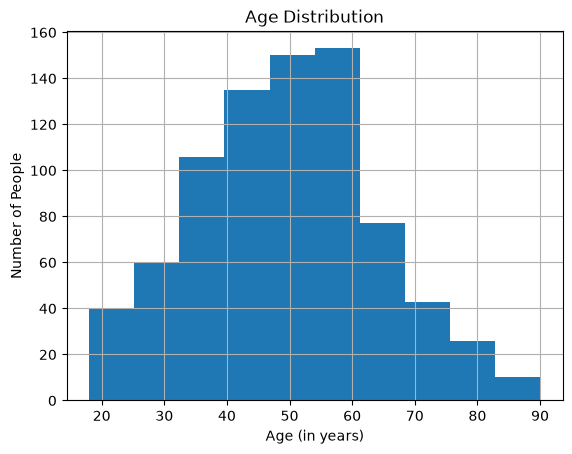

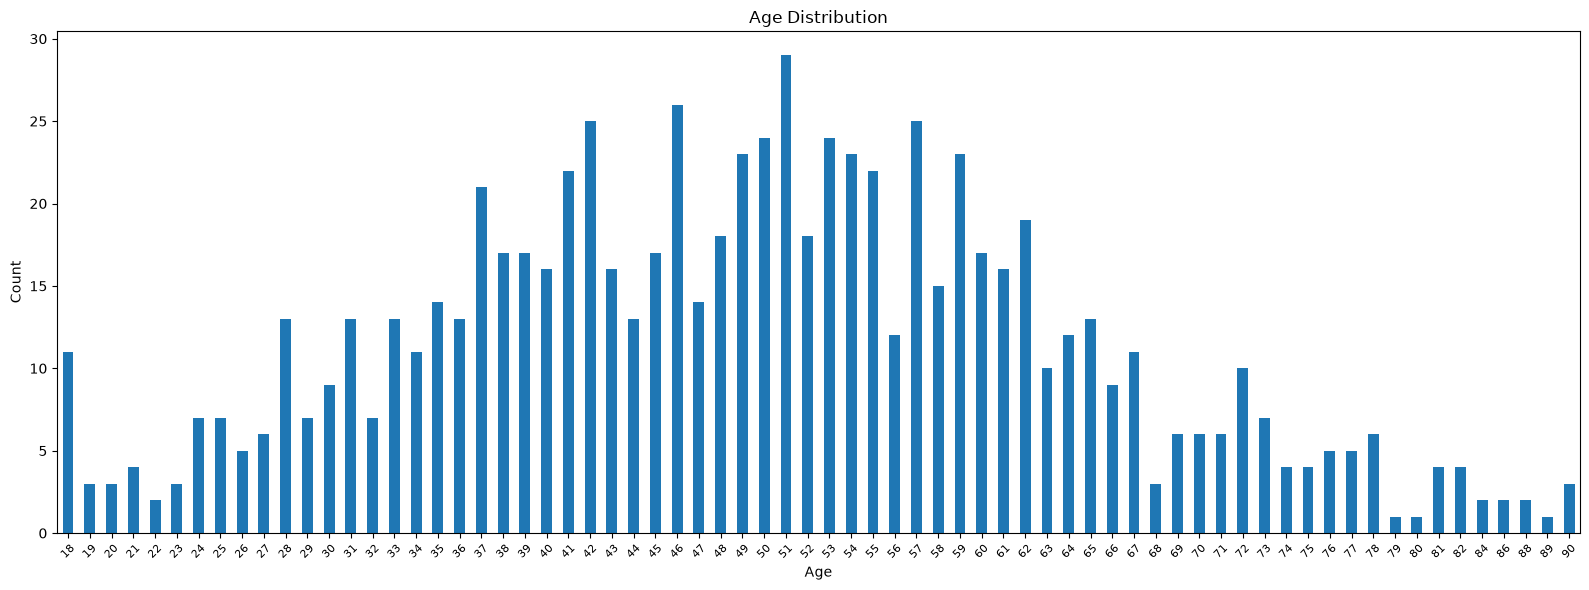

In [58]:
from src.visualization import plot_age_distribution, plot_age_counts

plot_age_distribution(df)
plot_age_counts(df)

3.2, Könsfördelning

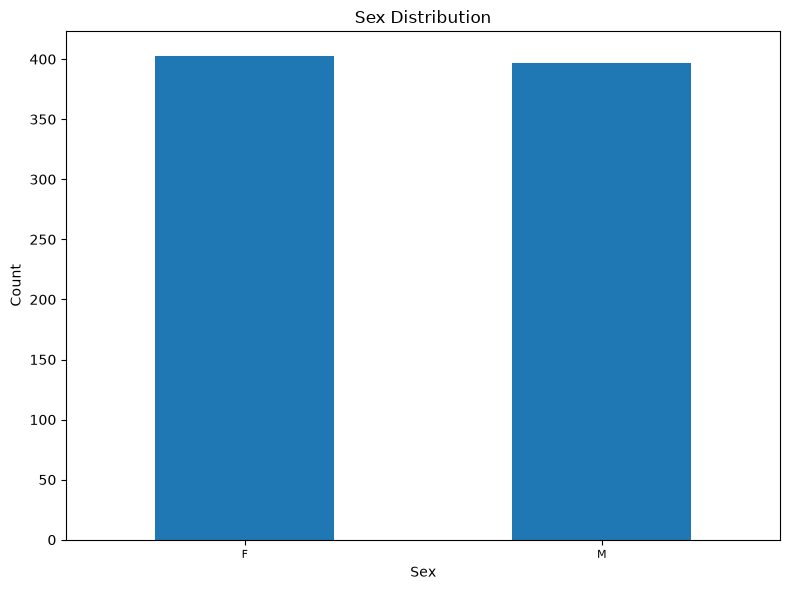

In [57]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_sex_distribution(df)

3.3 Längdfördelning

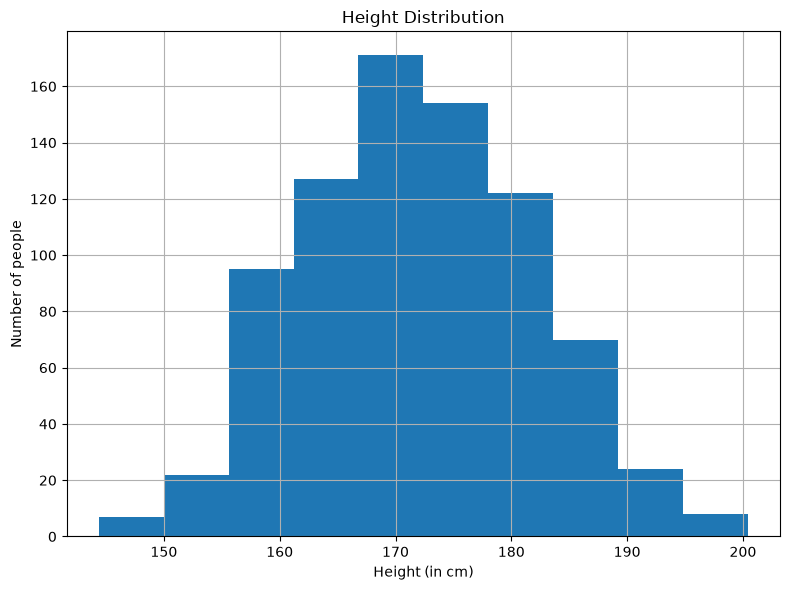

In [60]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_height_distribution(df)

Majoriteten av personerna verkar ha en längd mellan cirka 162 och 184 cm. Betydligt färre observationer förekommer runt 150 respektive 200 cm.

3.4, Viktfördelning

In [68]:
df["weight"].describe()

count    800.000000
mean      73.413000
std       13.685059
min       33.700000
25%       64.800000
50%       73.200000
75%       82.600000
max      114.400000
Name: weight, dtype: float64

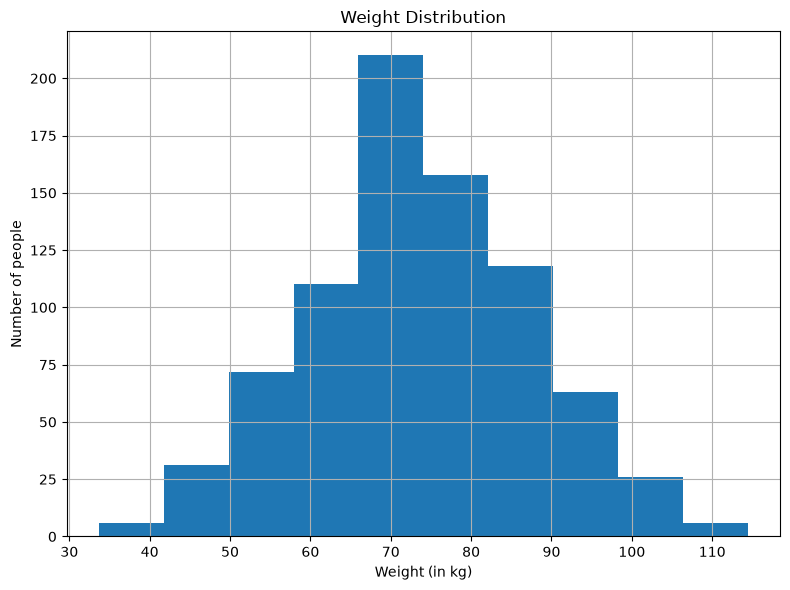

In [67]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_weight_distribution(df)

Den största koncentrationen av observationer ligger mellan cirka 66kg till 73kg. Drygt 200 personer återfinns inom detta viktintervall

3.5, Systolic_bp

In [69]:
df["systolic_bp"].describe()

count    800.000000
mean     149.178625
std       12.793360
min      106.800000
25%      140.900000
50%      149.400000
75%      157.600000
max      185.900000
Name: systolic_bp, dtype: float64

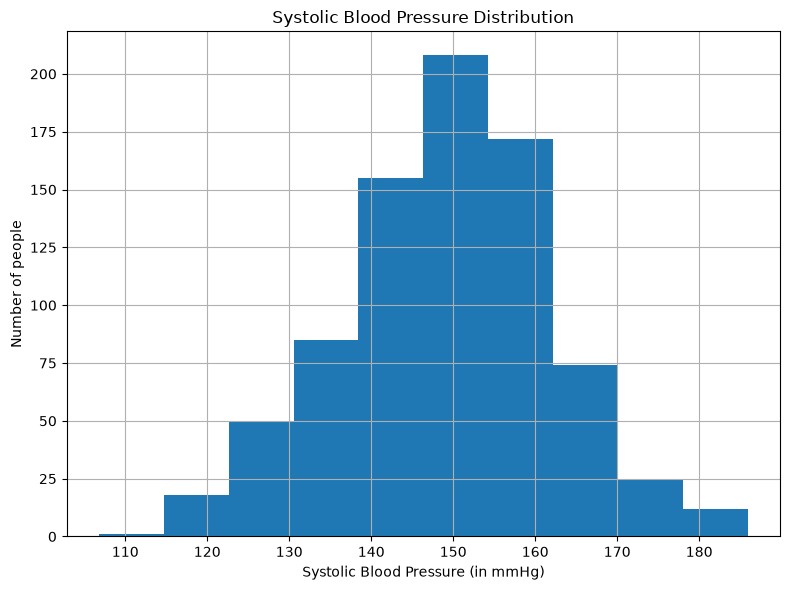

In [71]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_systolic_bp_distibution(df)

3.6, Kolesterol nivå

In [72]:
df["cholesterol"].describe()

count    800.000000
mean       4.929150
std        0.848413
min        2.500000
25%        4.327500
50%        4.970000
75%        5.482500
max        7.880000
Name: cholesterol, dtype: float64

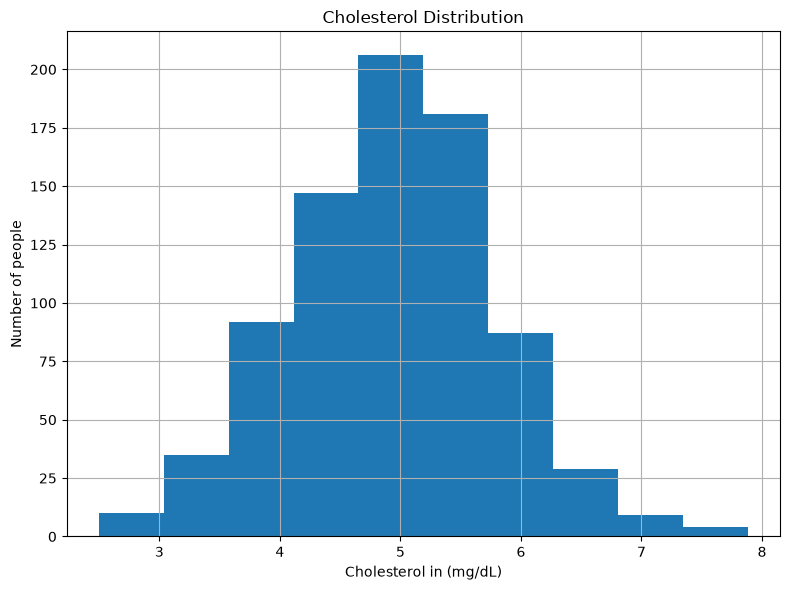

In [74]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_cholesterol_distribution(df)

3.7, Rökare

In [75]:
df["smoker"].describe()

count     800
unique      2
top        No
freq      587
Name: smoker, dtype: object

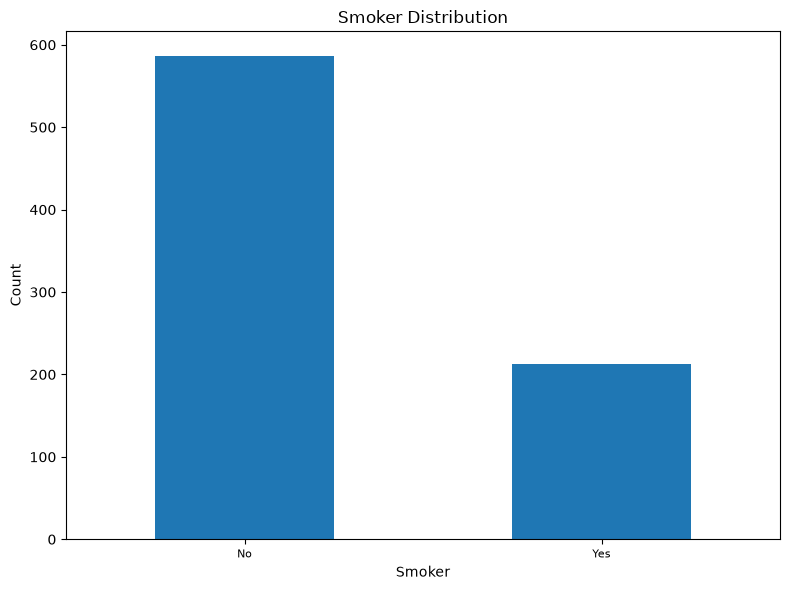

In [76]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_smoker_distribution(df)

3.8, Sjukdomar

In [78]:
df["disease"].value_counts()

disease
0    753
1     47
Name: count, dtype: int64

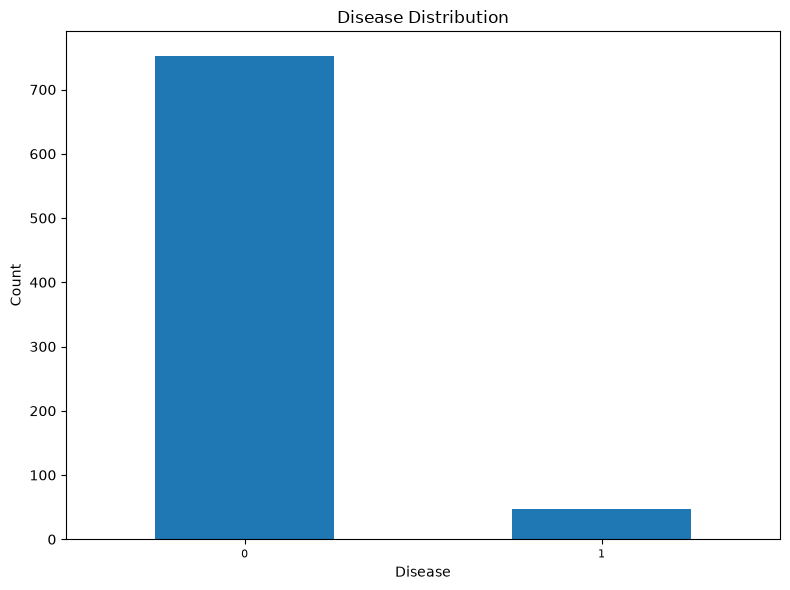

In [79]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_disease_distribution(df)

Endast 47 av de 800 personerna (5,9 %) har registrerats med en sjukdom, medan resterande 753 personer (94,1 %) saknar registrerad sjukdom. Detta innebär en tydlig obalans mellan grupperna, vilket är viktigt att ta hänsyn till vid vidare analys.

## 4. Beskrivande statistik

I detta avsnitt sammanställs grundläggande statistiska mått för datasetets numeriska variabler. Medelvärde, median, minimi- och maximivärde används för att ge en tydligare bild av variablernas värden och spridning.

In [80]:
df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(
    ["mean", "median", "std", "min", "max"]
)

,age,height,weight,systolic_bp,cholesterol
mean,49.426250,171.849250,73.413000,149.178625,4.929150
median,50.000000,171.350000,73.200000,149.400000,4.970000
std,14.501118,9.804259,13.685059,12.793360,0.848413
min,18.000000,144.400000,33.700000,106.800000,2.500000
max,90.000000,200.400000,114.400000,185.900000,7.880000


## 5. Simulering

I detta avsnitt genomförs en simulering med hjälp av NumPy. Syftet är att undersöka hur sjukdomsförekomsten kan se ut bland 1000 slumpmässigt genererade personer, baserat på sannolikheten i det ursprungliga datsetet

In [82]:
diesease_probability = df["disease"].mean()

print(diesease_probability)

0.05875


In [86]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import simulate_disease_probability

In [87]:
simulated_proportion = simulate_disease_probability(df)
print(simulated_proportion)

0.056


In [88]:
actual_proportion = df["disease"].mean()

print(f"Actual proportion: {actual_proportion: .2%}")
print(f"Simulated proportion: {simulated_proportion: .2%}")

Actual proportion:  5.88%
Simulated proportion:  5.60%


Simuleringen av 1 000 personer gav en sjukdomsförekomst på 5,6 %, jämfört med 5,88 % i det ursprungliga datasetet. Skillnaden är liten och visar att simuleringen ger ett resultat som ligger nära den faktiska sjukdomsförekomsten. Mindre variationer förväntas eftersom simuleringen bygger på slumpmässigt genererade värden.

In [89]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import calculate_confidence_interval

In [90]:
lower, upper = src.analysis.calculate_confidence_interval(df, "systolic_bp")

print(f"Lower limit: {lower:.2f}")
print(f"Upper limit: {upper:.2f}")

Lower limit: 148.29
Upper limit: 150.07


Konfidensintervallet för det genomsnittliga systoliska blodtrycket är 148,29–150,07 mmHg med 95 % konfidens. Intervallet är relativt smalt, vilket innebär att skattningen av medelvärdet har hög precision.

## 6. Hypotesprövning

In [93]:
df["smoker"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [94]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import test_smoker_blood_pressure

t_stat, p_value = test_smoker_blood_pressure(df)

print(f"Test statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

Test statistic: 0.4503
P-value: 0.3264


Hypotesprövningen genomfördes med Welch's t-test för att jämföra det genomsnittliga systoliska blodtrycket mellan rökare och icke-rökare.

Testet gav ett p-värde på 0,3264, vilket är högre än signifikansnivån 0,05. Därför kan nollhypotesen inte förkastas. Resultatet ger inte tillräckligt statistiskt stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare i detta dataset.